In [1]:
#Cell 1: Load the cleaned data
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import holidays
from scipy import stats
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import MSTL

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 4)

df = pd.read_csv("../data/processed/pjme_clean.csv", index_col="Datetime", parse_dates=True)
y = df["load_mw"]
print(y.shape, y.index.min(), "->", y.index.max())

(145392,) 2002-01-01 01:00:00 -> 2018-08-03 00:00:00


In [2]:
#Cell 2: Stationarity tests (ADF and KPSS)
def run_tests(series, name):
    adf_stat, adf_p = adfuller(series.dropna(), maxlag=48, autolag="AIC")[:2]
    kpss_stat, kpss_p = kpss(series.dropna(), regression="c", nlags="auto")[:2]
    print(f"{name:28s} ADF p = {adf_p:.4f} | KPSS p = {kpss_p:.4f}")

run_tests(y, "Original series")
run_tests(y.diff(1), "Differenced (lag 1)")
run_tests(y.diff(24), "Seasonal diff (lag 24)")
run_tests(y.diff(168), "Seasonal diff (lag 168)")

Original series              ADF p = 0.0000 | KPSS p = 0.0100
Differenced (lag 1)          ADF p = 0.0000 | KPSS p = 0.1000
Seasonal diff (lag 24)       ADF p = 0.0000 | KPSS p = 0.1000
Seasonal diff (lag 168)      ADF p = 0.0000 | KPSS p = 0.1000


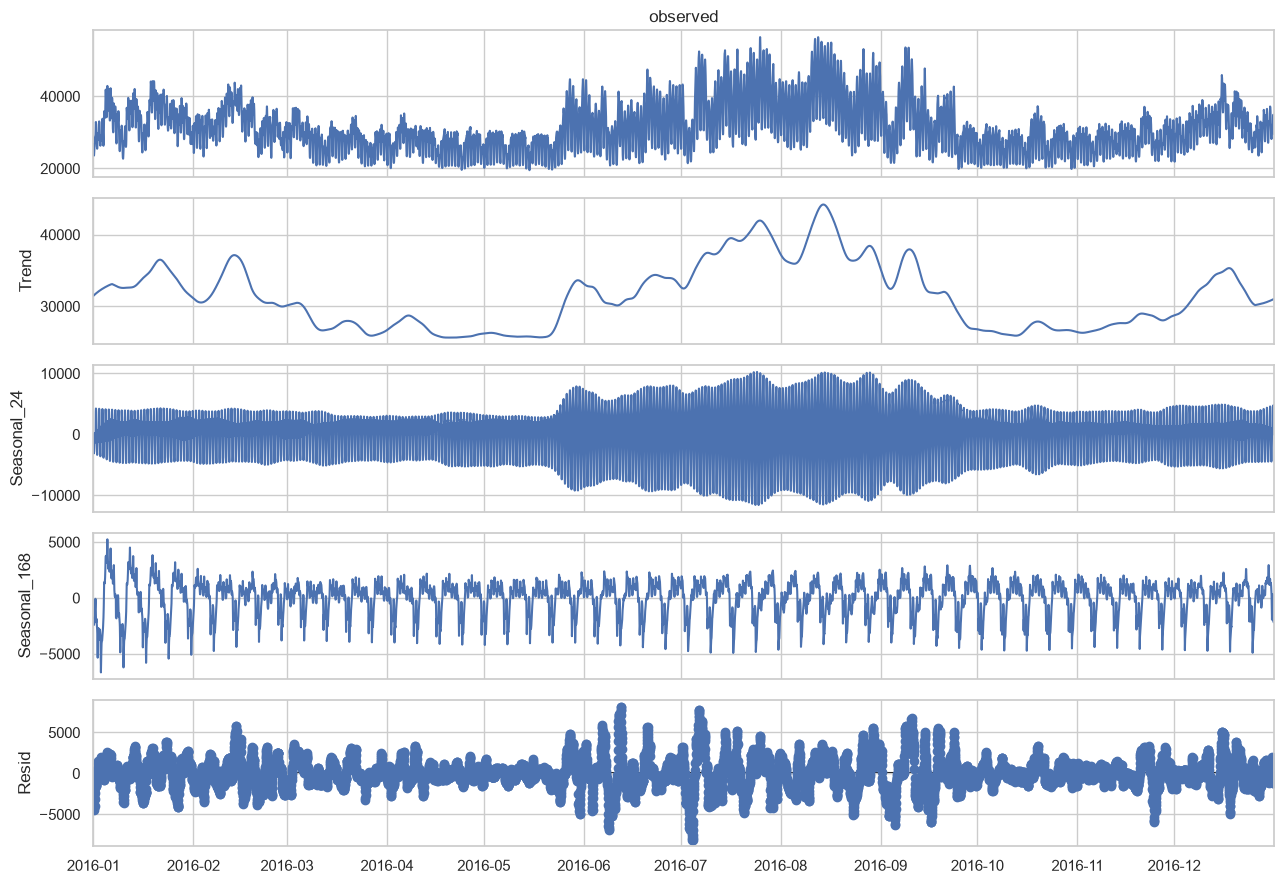

trend              0.448512
daily seasonal     0.384196
weekly seasonal    0.051166
residual           0.070943
dtype: float64


In [3]:
#Cell 2: Stationarity tests (ADF and KPSS)
sample = y["2016-01-01":"2016-12-31"]
res = MSTL(sample, periods=[24, 168]).fit()

fig = res.plot()
fig.set_size_inches(13, 9)
plt.tight_layout()
plt.savefig("../reports/figures/03_mstl_decomposition.png", dpi=150)
plt.show()

# Share of variance explained by each component
var_share = {
    "trend": res.trend.var(),
    "daily seasonal": res.seasonal["seasonal_24"].var(),
    "weekly seasonal": res.seasonal["seasonal_168"].var(),
    "residual": res.resid.var(),
}
print(pd.Series(var_share) / sample.var())

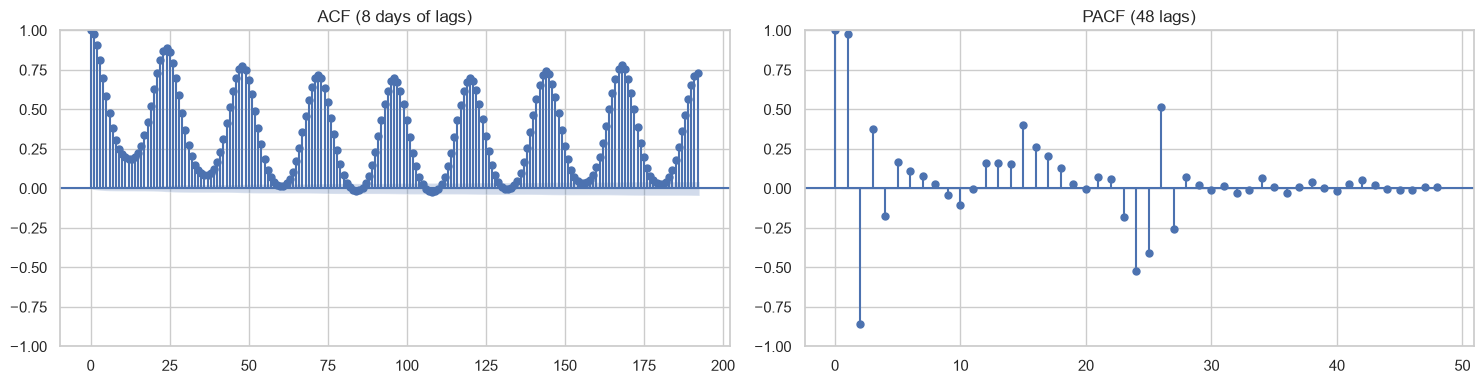

In [4]:
#Cell 4: ACF and PACF
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
plot_acf(y, lags=24 * 8, ax=ax[0])
ax[0].set_title("ACF (8 days of lags)")
plot_pacf(y, lags=48, method="ywm", ax=ax[1])
ax[1].set_title("PACF (48 lags)")
plt.tight_layout()
plt.savefig("../reports/figures/04_acf_pacf.png", dpi=150)
plt.show()

In [5]:
#Cell 5: Hypothesis tests
daily = y.resample("D").mean().to_frame("load")
daily["is_weekend"] = daily.index.dayofweek >= 5

us_hol = holidays.US(years=range(2002, 2019))
daily["is_holiday"] = daily.index.isin(pd.to_datetime(list(us_hol.keys())))

def compare(a, b, label):
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    d = (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)
    print(f"{label}")
    print(f"  mean A = {a.mean():,.0f} MW | mean B = {b.mean():,.0f} MW")
    print(f"  Mann-Whitney p = {p:.2e} | Cohen's d = {d:.2f}\n")

weekday = daily.loc[~daily["is_weekend"], "load"]
weekend = daily.loc[daily["is_weekend"], "load"]
compare(weekday, weekend, "Weekday (A) vs weekend (B)")

wd = daily[~daily["is_weekend"]]
compare(wd.loc[~wd["is_holiday"], "load"], wd.loc[wd["is_holiday"], "load"],
        "Normal weekday (A) vs weekday holiday (B)")

Weekday (A) vs weekend (B)
  mean A = 32,997 MW | mean B = 29,784 MW
  Mann-Whitney p = 9.27e-135 | Cohen's d = 0.73

Normal weekday (A) vs weekday holiday (B)
  mean A = 33,070 MW | mean B = 31,147 MW
  Mann-Whitney p = 8.88e-08 | Cohen's d = 0.45



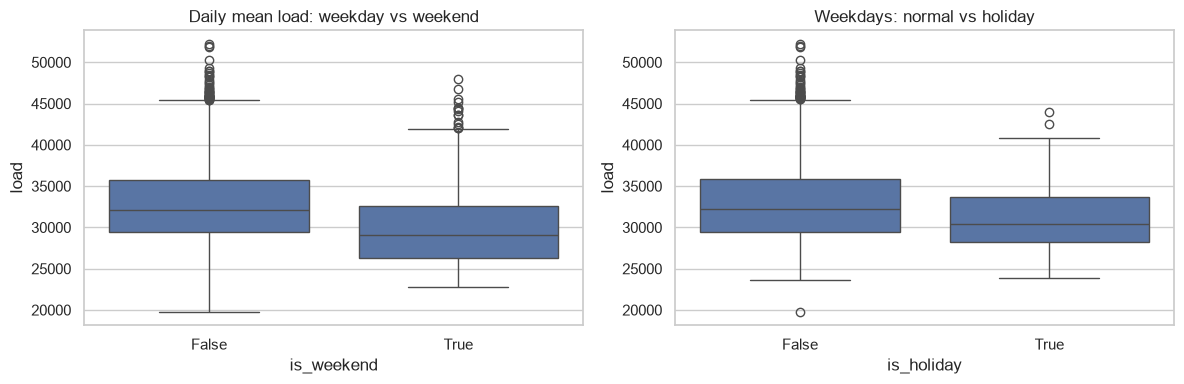

In [6]:
#Cell 6: Save a summary plot
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=daily, x="is_weekend", y="load", ax=ax[0])
ax[0].set_title("Daily mean load: weekday vs weekend")
sns.boxplot(data=wd, x="is_holiday", y="load", ax=ax[1])
ax[1].set_title("Weekdays: normal vs holiday")
plt.tight_layout()
plt.savefig("../reports/figures/05_group_comparisons.png", dpi=150)
plt.show()